# NIM: 2802392652
# Nama: Daniel Sebastian Winata

link video    

https://drive.google.com/drive/folders/17K43O6KpwYaRcoK1i91UJ13XC9ZucVRb?usp=sharing


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set(style="whitegrid")

In [10]:
df = pd.read_csv("B.csv")
df.head()

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
0,1,Male,53,79,56,8.87,50,92,90,1,3,23,4,91,4,Yes,0,0.00
1,2,Female,56,54,59,6.78,61,51,99,1,0,6,5,87,3,No,0,0.00
2,3,Male,94,83,83,7.92,91,93,84,1,1,10,2,81,2,No,1,6.92
3,4,Male,84,71,87,6.57,85,60,72,4,2,14,5,87,3,No,0,0.00
4,5,Male,58,88,74,9.01,73,52,88,1,2,20,0,60,1,No,0,0.00


In [11]:
df.shape

(5000, 18)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.columns.tolist()

['student_id',
 'gender',
 'ssc_percentage',
 'hsc_percentage',
 'degree_percentage',
 'cgpa',
 'entrance_exam_score',
 'technical_skill_score',
 'soft_skill_score',
 'internship_count',
 'live_projects',
 'work_experience_months',
 'certifications',
 'attendance_percentage',
 'backlogs',
 'extracurricular_activities',
 'placement_status',
 'salary_package_lpa']

data mahasiswa dengan 5000 baris. Terdapat dua target utama, yaitu    
placement_status untuk klasifikasi   
salary_package_lpa untuk regresi

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  5000 non-null   int64  
 1   gender                      5000 non-null   object 
 2   ssc_percentage              5000 non-null   int64  
 3   hsc_percentage              5000 non-null   int64  
 4   degree_percentage           5000 non-null   int64  
 5   cgpa                        5000 non-null   float64
 6   entrance_exam_score         5000 non-null   int64  
 7   technical_skill_score       5000 non-null   int64  
 8   soft_skill_score            5000 non-null   int64  
 9   internship_count            5000 non-null   int64  
 10  live_projects               5000 non-null   int64  
 11  work_experience_months      5000 non-null   int64  
 12  certifications              5000 non-null   int64  
 13  attendance_percentage       5000 

In [15]:
df = df.drop(columns=['student_id','backlogs']) # ga berguna

student id adalah identifier yang tidak berguna untuk analsis,    

Backlogs secara teknis artinya: mahasiswa yang memiliki tunggakan biaya mata kuliah (kgk bs lulus). Jadi modelnya udah tau kalau backlogs diatas 0 = unemployed

In [16]:
df['placement_status'].value_counts()

placement_status
0    4134
1     866
Name: count, dtype: int64

In [17]:
df['extracurricular_activities'].value_counts()

extracurricular_activities
No     2553
Yes    2447
Name: count, dtype: int64

In [18]:
df.describe()

,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,placement_status,salary_package_lpa
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,72.425800,71.910800,71.845200,7.678326,69.197800,69.651000,69.839600,1.987800,2.491800,11.982000,2.481000,79.433400,0.173200,1.59589
std,13.199642,12.842781,10.013196,1.237084,17.325528,17.179704,17.170732,1.410975,1.704967,7.258114,1.719485,11.638585,0.378458,3.77582
min,50.000000,50.000000,55.000000,5.500000,40.000000,40.000000,40.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,0.00000
25%,61.000000,61.000000,63.000000,6.617500,54.000000,55.000000,55.000000,1.000000,1.000000,6.000000,1.000000,69.000000,0.000000,0.00000
50%,72.000000,72.000000,72.000000,7.700000,69.000000,70.000000,69.000000,2.000000,3.000000,12.000000,2.000000,80.000000,0.000000,0.00000
75%,84.000000,83.000000,80.000000,8.750000,84.000000,84.000000,85.000000,3.000000,4.000000,18.000000,4.000000,89.000000,0.000000,0.00000
max,95.000000,94.000000,89.000000,9.800000,99.000000,99.000000,99.000000,4.000000,5.000000,24.000000,5.000000,99.000000,1.000000,14.99000


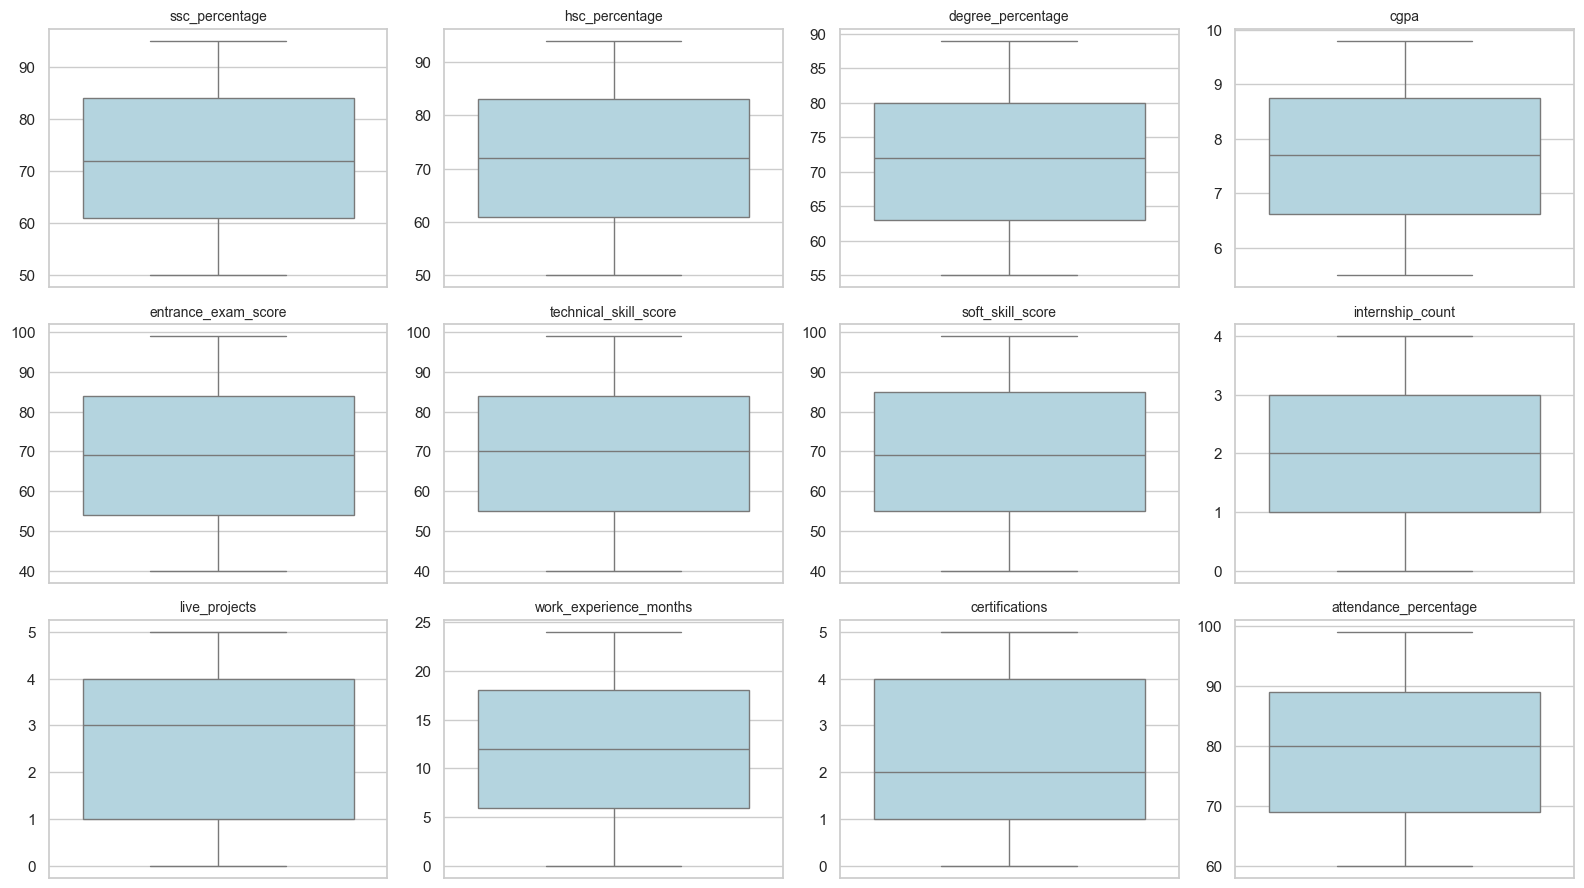

In [19]:
numcol = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
catcol = df.select_dtypes(include=['object']).columns.tolist()

cols_to_plot = [col for col in numcol if col not in ['student_id', 'placement_status', 'salary_package_lpa']]


# ukuran
plt.figure(figsize=(16, 12))

for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(4, 4, i)  #   grid 4x4
    sns.boxplot(y=df[col], color='lightblue')
    plt.title(col, fontsize=10)
    plt.ylabel('')

plt.tight_layout()
plt.show()

tidak terdapat outlier atau nilai2 ekstrim di fitur2

Tetapi saya tidak akan rule out outliers terlebih dahulu, saya melkaukan explorasi lebih lanjut

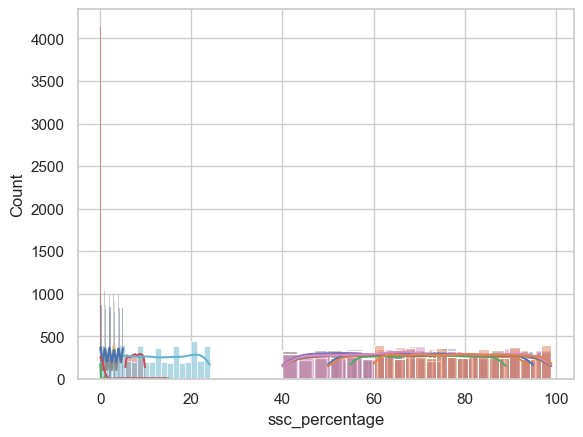

In [21]:
for col in numcol:
    sns.histplot(df[col], kde=True)

sebagian besar nilai berada pada rentang menengah hingga tinggi (sekitar 60–90), meskipun terdapat beberapa nilai rendah

<Axes: xlabel='placement_status', ylabel='count'>

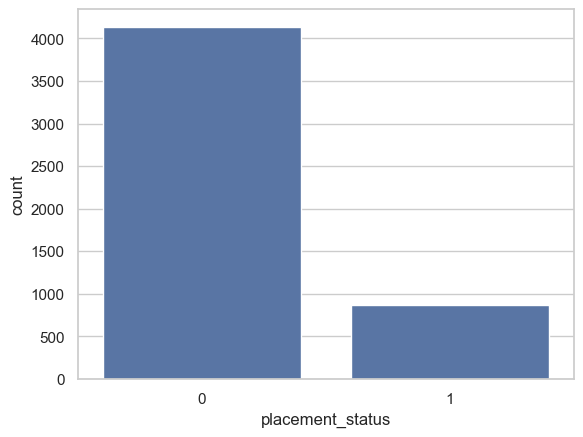

In [22]:
sns.countplot(x='placement_status', data=df)

TERDAPAT IMBALANCE yang TINGGI   
Jumlah data dengan status 0 ( yg tidak ditempatkan ) jauh lebih banyak dibandingkan status 1 (ditempatkan)    
Ketidakseimbangan ini bisa mempengaruhi performa model machine learning, terutama model yang sensitif terhadap distribusi kelas seperti Logistic Regression.

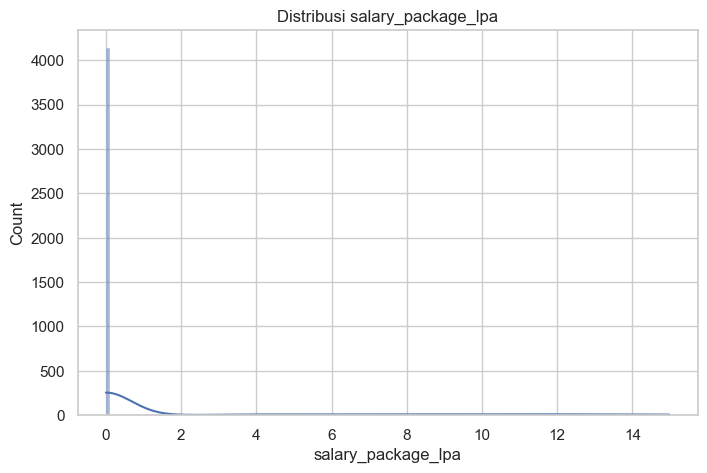

In [23]:
plt.figure(figsize=(8,5))
sns.histplot(df['salary_package_lpa'], kde=True)
plt.title("Distribusi salary_package_lpa")
plt.show()

Meskipun mayoritas data berada di angka 0, garis KDE (garis biru melengkung) dan sumbu X yang memanjang hingga angka 14-15 menunjukkan adanya outliers. Ada segelintir data dengan nilai gaji yang jauh lebih besar (misalnya 2, 4, hingga 15 LPA), tetapi jumlahnya sangat sedikit sehingga batang histogramnya nyaris tidak terlihat secara visual dan rata dengan sumbu X

distribusi tidak normal

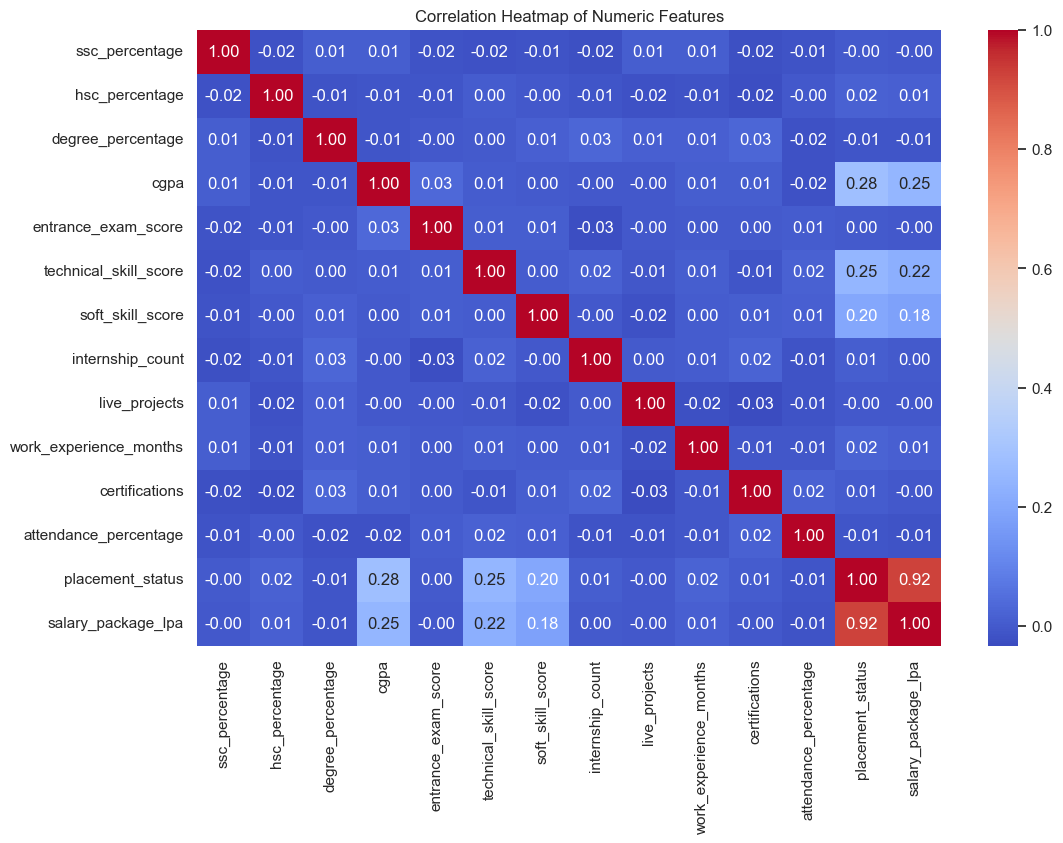

In [24]:

plt.figure(figsize=(12, 8))
# Tambahkan numeric_only=True di dalam corr()
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

dari heatmap diatas, bisa dilihat bahwa   
terdapat korelasi positif yang sangat tinggi (0.92) antara placement_status dan salary_package_lpa. ini sangat masuk akal karena mahasiswa yang tidak mendapat pekerjaan otomatis memiliki gaji 0. 

untuk mencegah data leakage (model yg kerjanya nyontek jawaban), kolom salary_package_lpa didrop saat melatih model klasifikasi kelulusan, dan sebaliknya

yangg nilai2 positive: cgpa dengan skor 0.28 dan technical_skill_score dengan skor 0.25 itu dua metrik terkuat yang berbanding lurus dengan probabilitas seorang mahasiswa mendapatkan pekerjaan dan besaran gajinya
Aslinya soft_skill_score dengan skor 0.20 juga memiliki peran positif, tapi ga sekuat kemampuan teknis

fitur dengan Pengaruh Rendah: Cukup mengejutkan bahwa pengalaman praktis seperti internship_count, live_projects, dan work_experience_months menunjukkan korelasi linear yang mendekati nol (0.00 hingga -0.02) terhadap target. 



Model non-linear seperti Random Forest atau XGBoost mungkin diperlukan untuk dapat pola tersembunyi dari fitur-fitur ini kalau ada

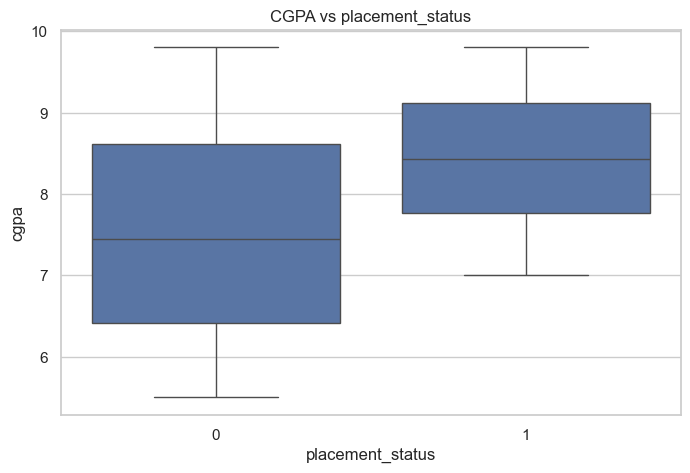

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(x='placement_status', y='cgpa', data=df)
plt.title("CGPA vs placement_status")
plt.show()

CGPA dapat menjadi fitur yang kuat untuk klasifikasi placement status karena memiliki boxplot yang lebih tinggi daripada 0 

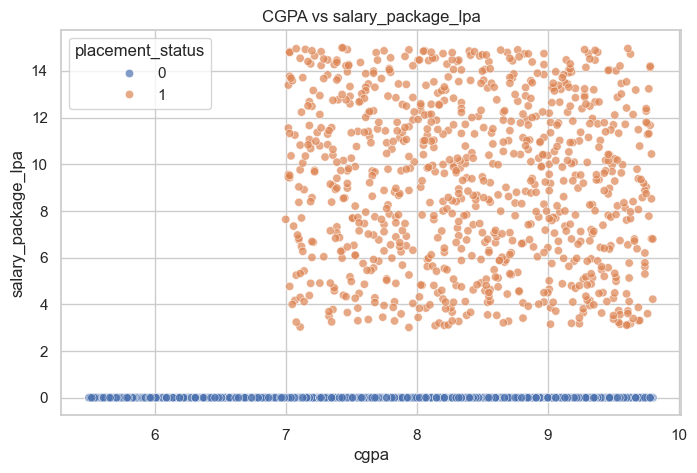

In [26]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='cgpa', y='salary_package_lpa', hue='placement_status', alpha=0.7)
plt.title("CGPA vs salary_package_lpa")
plt.show()

Scatterplot digunakan untuk melihat apakah ada hubungan antara performa akademik dan besaran gaji. Jika terlihat tren naik, maka CGPA cenderung memiliki hubungan positif dengan salary package. Ini menjadi dasar penting dalam pemodelan regresi

grafik tersebut tidak menunjukkan tren naik sama sekali. Untuk mahasiswa yang berhasil mendapat pekerjaan (titik oranye), sebaran gajinya terlihat acak pada rentang 3 hingga 15 LPA. Mahasiswa dengan CGPA 7.0 bisa mendapatkan gaji tinggi (misal 14 LPA), dan sebaliknya, mahasiswa dengan CGPA 9.5 juga bisa mendapatkan gaji di bawah (misal 4 LPA)

jadi semua yang tidak punya pekerjaan dianggap memiliki gaji 0
sementara yang punya pekerjaan bergaji

# SPLIT DATA ( CLF DAN REG ) + PREPROCESSOR

In [27]:
# CLASSIFICATION PERTAMA
# kita akan namain classification dengean clf dan regresi dengan reg

X_clf = df.drop(columns=['placement_status', 'salary_package_lpa'])
y_clf = df['placement_status']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=42
)

num_cols_clf = X_train_clf.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols_clf = X_train_clf.select_dtypes(include=['object']).columns.tolist()

pakai stratify agar rasio imbalanced kelas 0 dan 1 tetap terjaga

In [28]:
df.isna().sum()

gender                        0
ssc_percentage                0
hsc_percentage                0
degree_percentage             0
cgpa                          0
entrance_exam_score           0
technical_skill_score         0
soft_skill_score              0
internship_count              0
live_projects                 0
work_experience_months        0
certifications                0
attendance_percentage         0
extracurricular_activities    0
placement_status              0
salary_package_lpa            0
dtype: int64

numerik bakal diproses menggunakan simpleImputer (strategi median agar tahan outklier, KENAPA? walau saat explorasi kita tidak melihat terdapat outlier, strategi mean adalah strategi yang sangat ideal just in case supaya data tidak skew. Karena kalau pakai mean, jika ternyata terdapat outlier, nilai mean akan sangat berbeda dan menyebabkan imputasi yang teralu jauh)

Dalam dataset ini juga tidak memiliki missing values. Walaupun tidak ada data sama sekali untuk diimputasi, tetap memasukannya adalah best practice

dan pakai StandardScaler. Kenapa? Standardscaler itu cocok untuk dipakai saat menggunakan algoritma yang berbasis jarak atau optimasi, seperti SVM (Support Vector Machines), K-Nearest Neighbors (KNN), atau Regresi Linear/Logistik   

kategorikal seperti kolom gender sama extracurricular_activities bakal diproses menggunakan OneHotEncoder. Ini dipilih karena data kategorikal tersebut bersifat nominal (ga memiliki tingkatan/urutan matematis)   

Kedua proses ini digabungkan secara elegan menggunakan ColumnTransformer buat mencegah data leakage selama proses testing

In [29]:
#PREPROCESSOR BUAT CLASSIFICATION

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_clf = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols_clf),
        ('cat', categorical_transformer, cat_cols_clf)
    ]
)

In [30]:
# REGRESSION

X_reg = df.drop(columns=['salary_package_lpa', 'placement_status'])
y_reg = df['salary_package_lpa']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

num_cols_reg = X_train_reg.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols_reg = X_train_reg.select_dtypes(include=['object']).columns.tolist()

In [31]:
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols_reg),
        ('cat', categorical_transformer, cat_cols_reg)
    ]
)

# CLASSIFICATION MODELLING

milih algoritma2 buat nentukan mana yang paling bagus

Random Forest: Random Forest dipilih untuk menangkap interaksi non-linear yang kompleks antar fitur   

XGboost : algoritma machine learning yang sangat populer dan kuat, terutama untuk data tabular

LightGBM: khusus untuk efisiensi, kecepatan, dan penggunaan memori yang rendah, terutama pada dataset berukuran besar

Numerik diimputasi pakai median. INI karena median lebih tahan terhadap outlier, walau data tidak memiliki msising value ini itu best practice yang bagus untuk diinclude    

In [32]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier 


ratio = float(y_train_clf.value_counts()[0] / y_train_clf.value_counts()[1])

clf_models = {
    "XGBoost": XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss'),
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    "LightGBM": LGBMClassifier(scale_pos_weight=ratio, random_state=42, verbose=-1)
}

clf_results = []

for name, model in clf_models.items():
    clf_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor_clf), 
        ('model', model)
    ])
    
    clf_pipe.fit(X_train_clf, y_train_clf)
    y_pred = clf_pipe.predict(X_test_clf)
    
    clf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_clf, y_pred),
        "Precision": precision_score(y_test_clf, y_pred, zero_division=0),
        "Recall": recall_score(y_test_clf, y_pred, zero_division=0),
        "F1": f1_score(y_test_clf, y_pred, zero_division=0)
    })
    
    print(f"\n{name}")
    print(classification_report(y_test_clf, y_pred, zero_division=0))

clf_results_df = pd.DataFrame(clf_results)
display(clf_results_df)


XGBoost
              precision    recall  f1-score   support

           0       0.92      0.87      0.90       827
           1       0.52      0.65      0.57       173

    accuracy                           0.83      1000
   macro avg       0.72      0.76      0.74      1000
weighted avg       0.85      0.83      0.84      1000


Random Forest
              precision    recall  f1-score   support

           0       0.86      0.95      0.90       827
           1       0.53      0.28      0.37       173

    accuracy                           0.83      1000
   macro avg       0.70      0.62      0.64      1000
weighted avg       0.81      0.83      0.81      1000


LightGBM
              precision    recall  f1-score   support

           0       0.96      0.84      0.90       827
           1       0.53      0.84      0.65       173

    accuracy                           0.84      1000
   macro avg       0.74      0.84      0.77      1000
weighted avg       0.89      0.84      0

,Model,Accuracy,Precision,Recall,F1
0,XGBoost,0.834,0.516129,0.647399,0.574359
1,Random Forest,0.833,0.532609,0.283237,0.369811
2,LightGBM,0.841,0.525362,0.838150,0.645880


saya tidak melakukan tuning untuk classification. Hal ini dikarenakan nilai nilai metrik yang teralu banyak meraih angka 1.0   
angka tersebut sangatlah tidak realistis dalam membuat prediksi untuk data real.  
Oleh karena itu, saya akan meghindari tuning untuk classification.

# REGRESSION MODELLING

Model yang dipakai:

Linear Regression       : digunakan ketika ingin memprediksi nilai numerik yang berkelanjutan (kontinu) berdasarkan satu atau lebih variabel input
RandomForestRegressor   : cocok Ketika hubungan antara fitur (variabel bebas) dan label (variabel target) sangat kompleks dan non-linear.
XGBoost                 : Sangat cepat dan efisien dalam pemrosesan data besar, dan dapat mencegah overfitting

In [33]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=42)
}

reg_results = []

for name, model in reg_models.items():
    print(f"Memproses {name}...")
    
    reg_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor_reg),
        ('model', model)
    ])
    

    reg_pipe.fit(X_train_reg, y_train_reg)
    
    y_pred_reg = reg_pipe.predict(X_test_reg)
    
  
    mae = mean_absolute_error(y_test_reg, y_pred_reg)
    rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
    r2 = r2_score(y_test_reg, y_pred_reg)
    
    # log hasil
    reg_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })


reg_results_df = pd.DataFrame(reg_results)
display(reg_results_df)

Memproses Linear Regression...
Memproses Random Forest...
Memproses XGBoost...


,Model,MAE,RMSE,R2 Score
0,Linear Regression,2.452383,3.574003,0.146534
1,Random Forest,1.737359,3.185942,0.321809
2,XGBoost,2.201838,3.452634,0.203516


nilai r2 score teralu kecil, kita akan melakukan tuning dengan fokus r2

In [34]:
from sklearn.model_selection import GridSearchCV

import pandas as pd
pd.set_option('display.max_colwidth', None)

reg_models_tune = { #linear regression tidak ada parameter untuk tuning
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}


param_grids_reg = {
    "Random Forest": {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [10, 20, None],
        'model__min_samples_split': [5, 10, 20] # Diperbesar agar tidak overfit
    },
    "XGBoost": {
        'model__max_depth': [3, 5, 7],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__n_estimators': [100, 200, 300]
    }
}

tuned_reg_results = []
best_reg_estimators = {}

for name, model in reg_models_tune.items():
    print(f"=== Sedang Tuning {name} ===")
    
    reg_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor_reg),
        ('model', model)
    ])
    
    #  R2 metrik scoring
    grid_search_reg = GridSearchCV(
        estimator=reg_pipe,
        param_grid=param_grids_reg[name],
        cv=5,
        scoring='r2', 
        n_jobs=-1,
        verbose=1
    )
    
    grid_search_reg.fit(X_train_reg, y_train_reg)
    
    best_model = grid_search_reg.best_estimator_
    best_reg_estimators[name] = best_model
    
    y_pred_reg = best_model.predict(X_test_reg)
    
    tuned_reg_results.append({
        "Model": name,
        "Best Params": str(grid_search_reg.best_params_),
        "MAE": mean_absolute_error(y_test_reg, y_pred_reg),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
        "R2 Score": r2_score(y_test_reg, y_pred_reg)
    })

tuned_reg_df = pd.DataFrame(tuned_reg_results)
display(tuned_reg_df)

=== Sedang Tuning Random Forest ===
Fitting 5 folds for each of 27 candidates, totalling 135 fits
=== Sedang Tuning XGBoost ===
Fitting 5 folds for each of 27 candidates, totalling 135 fits


,Model,Best Params,MAE,RMSE,R2 Score
0,Random Forest,"{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}",1.722231,3.152973,0.335773
1,XGBoost,"{'model__learning_rate': 0.01, 'model__max_depth': 3, 'model__n_estimators': 200}",1.833145,3.132673,0.344298


kenapa gridsearchCV?

ketika ingin menemukan kombinasi hyperparameter terbaik untuk model machine learning Anda secara sistematis dan otomatis,   
gridsearchCV adalah yang paling optimal walau dapat memakan waktu lama dibanding randomizedsearchCV.    

Nilai R² umumnya berkisar antara 0 hingga 1.    
0: Berarti model tidak menjelaskan variasi apa pun dari variabel dependen.   
1: Berarti model menjelaskan seluruh variasi variabel dependen.   

pemenang   
Classification : LightGBM karena memiliki nilai f1 score tertinggi dari ketiga model   
Regression     : XGBoost (tuned) karena menunjukan nilai R2 score yang paling bagus